<a href="https://colab.research.google.com/github/suryasaraschandra/MINOR-PROJECT-1/blob/main/Surya_minorproject1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [108]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("/content/car_price_prediction_.csv")
df.head()
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car ID        2500 non-null   int64  
 1   Brand         2500 non-null   object 
 2   Year          2500 non-null   int64  
 3   Engine Size   2500 non-null   float64
 4   Fuel Type     2500 non-null   object 
 5   Transmission  2500 non-null   object 
 6   Mileage       2500 non-null   int64  
 7   Condition     2500 non-null   object 
 8   Price         2500 non-null   float64
 9   Model         2500 non-null   object 
dtypes: float64(2), int64(3), object(5)
memory usage: 195.4+ KB


,Car ID,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Price,Model
0,1,Tesla,2016,2.3,Petrol,Manual,114832,New,26613.92,Model X
1,2,BMW,2018,4.4,Electric,Manual,143190,Used,14679.61,5 Series
2,3,Audi,2013,4.5,Electric,Manual,181601,New,44402.61,A4
3,4,Tesla,2011,4.1,Diesel,Automatic,68682,New,86374.33,Model Y
4,5,Ford,2009,2.6,Diesel,Manual,223009,Like New,73577.10,Mustang


In [109]:
df.shape

(2500, 10)

In [110]:
df.columns

Index(['Car ID', 'Brand', 'Year', 'Engine Size', 'Fuel Type', 'Transmission',
       'Mileage', 'Condition', 'Price', 'Model'],
      dtype='object')

In [111]:
df.isnull().sum()


,0
Car ID,0
Brand,0
Year,0
Engine Size,0
Fuel Type,0
Transmission,0
Mileage,0
Condition,0
Price,0
Model,0


In [112]:
df.duplicated().sum()

np.int64(0)

In [113]:
# To reduce unecessary spaces gaps

In [114]:
df.head()
df.sort_values(by="Year",inplace=True)
df.reset_index(inplace=True)
df

,index,Car ID,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Price,Model
0,2421,2422,Toyota,2000,5.6,Diesel,Manual,278606,Like New,61357.58,Corolla
1,2427,2428,Ford,2000,2.7,Petrol,Manual,22222,New,81902.35,Explorer
2,40,41,Mercedes,2000,3.9,Petrol,Manual,204120,New,36094.75,E-Class
3,2412,2413,Audi,2000,5.1,Hybrid,Automatic,179810,New,40899.14,A3
4,818,819,Audi,2000,5.6,Petrol,Automatic,254809,Used,74765.48,Q7
...,...,...,...,...,...,...,...,...,...,...,...
2495,1175,1176,Tesla,2023,3.3,Petrol,Manual,295531,Like New,88851.63,Model X
2496,2084,2085,BMW,2023,5.5,Electric,Automatic,168332,Used,24135.18,3 Series
2497,787,788,Mercedes,2023,1.4,Electric,Manual,57803,New,16248.15,E-Class
2498,2476,2477,Tesla,2023,4.1,Electric,Automatic,83100,Like New,37331.49,Model X


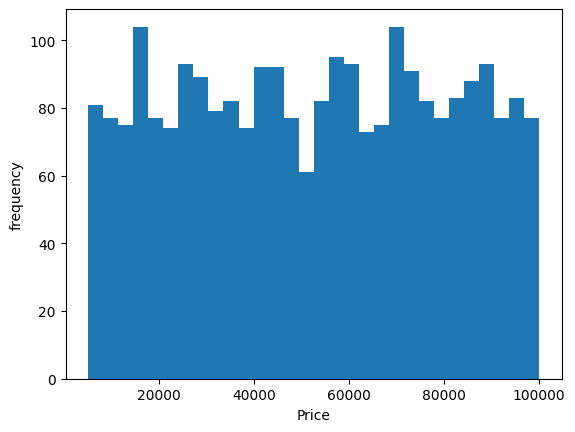

In [115]:
#univariate
plt.hist(df["Price"],bins=30)
plt.xlabel("Price")
plt.ylabel("frequency")
plt.show()

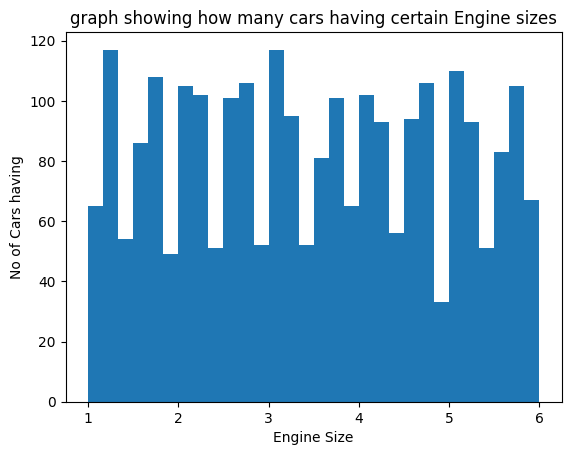

In [116]:
# FOR ENGINE SIZE
plt.hist(df["Engine Size"],bins=30)
plt.xlabel("Engine Size")
plt.ylabel("No of Cars having")
plt.title("graph showing how many cars having certain Engine sizes")
plt.show()

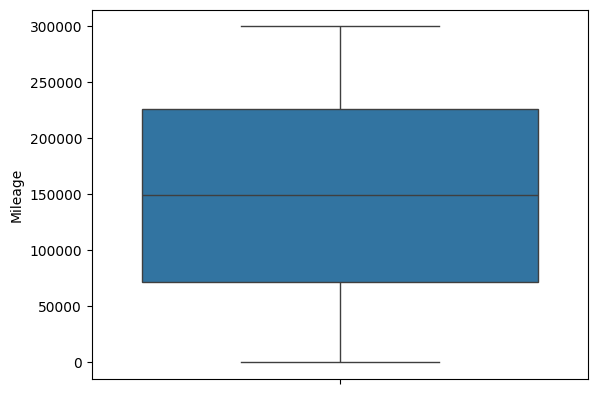

In [117]:
#FOR MILEAGE
sns.boxplot(df["Mileage"])
plt.show()

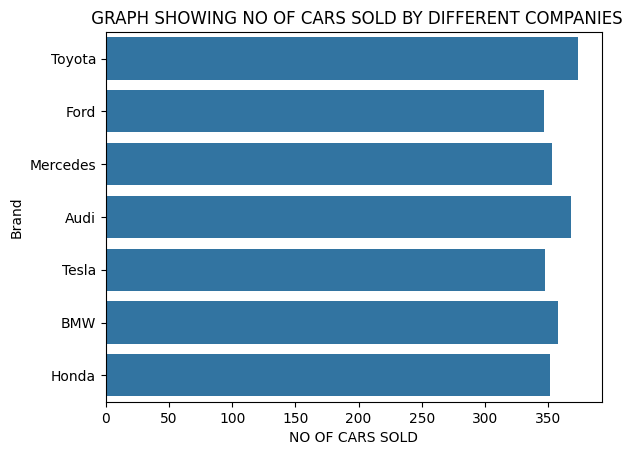

In [118]:
# FOR BRAND
sns.countplot(df["Brand"])
plt.xlabel("NO OF CARS SOLD")
plt.title(" GRAPH SHOWING NO OF CARS SOLD BY DIFFERENT COMPANIES")
plt.show()

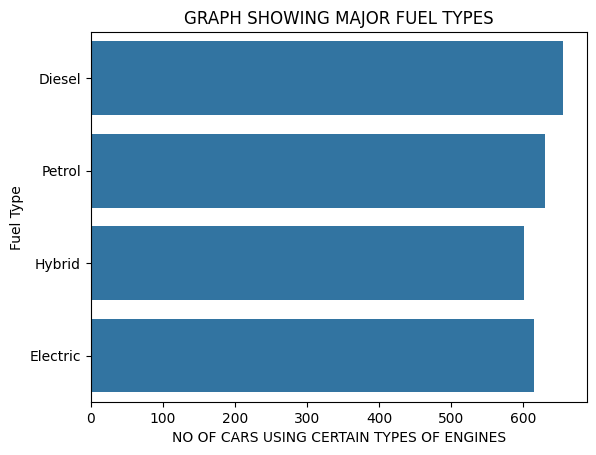

In [119]:
#ABOUT TYPE OF FUEL
sns.countplot(df["Fuel Type"])
plt.xlabel("NO OF CARS USING CERTAIN TYPES OF ENGINES")
plt.title("GRAPH SHOWING MAJOR FUEL TYPES")
plt.show()

In [120]:
# FIND RELATIONS

fuel=pd.crosstab(df["Brand"],df["Fuel Type"])
fuel

Fuel Type,Diesel,Electric,Hybrid,Petrol
Brand,,,,
Audi,97,94,81,96
BMW,92,91,86,89
Ford,85,85,86,91
Honda,103,75,87,87
Mercedes,83,82,80,108
Tesla,88,100,85,75
Toyota,107,87,96,84


<Axes: xlabel='Brand', ylabel='Electric'>

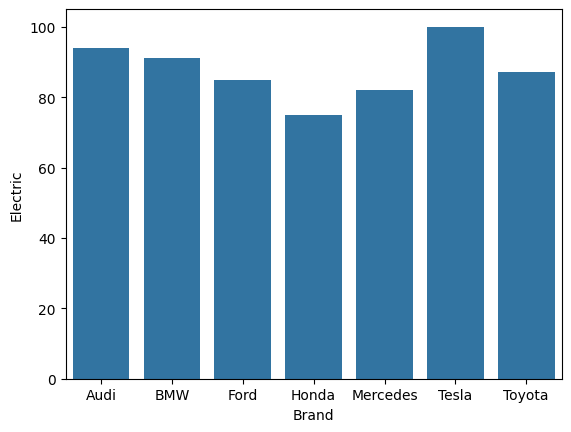

In [121]:
sns.barplot(fuel.loc[:,"Electric"])
#WE CAN IDENTIFY WHICH CAR IS USING ELECTRIC FUEL MORE.


<BarContainer object of 7 artists>

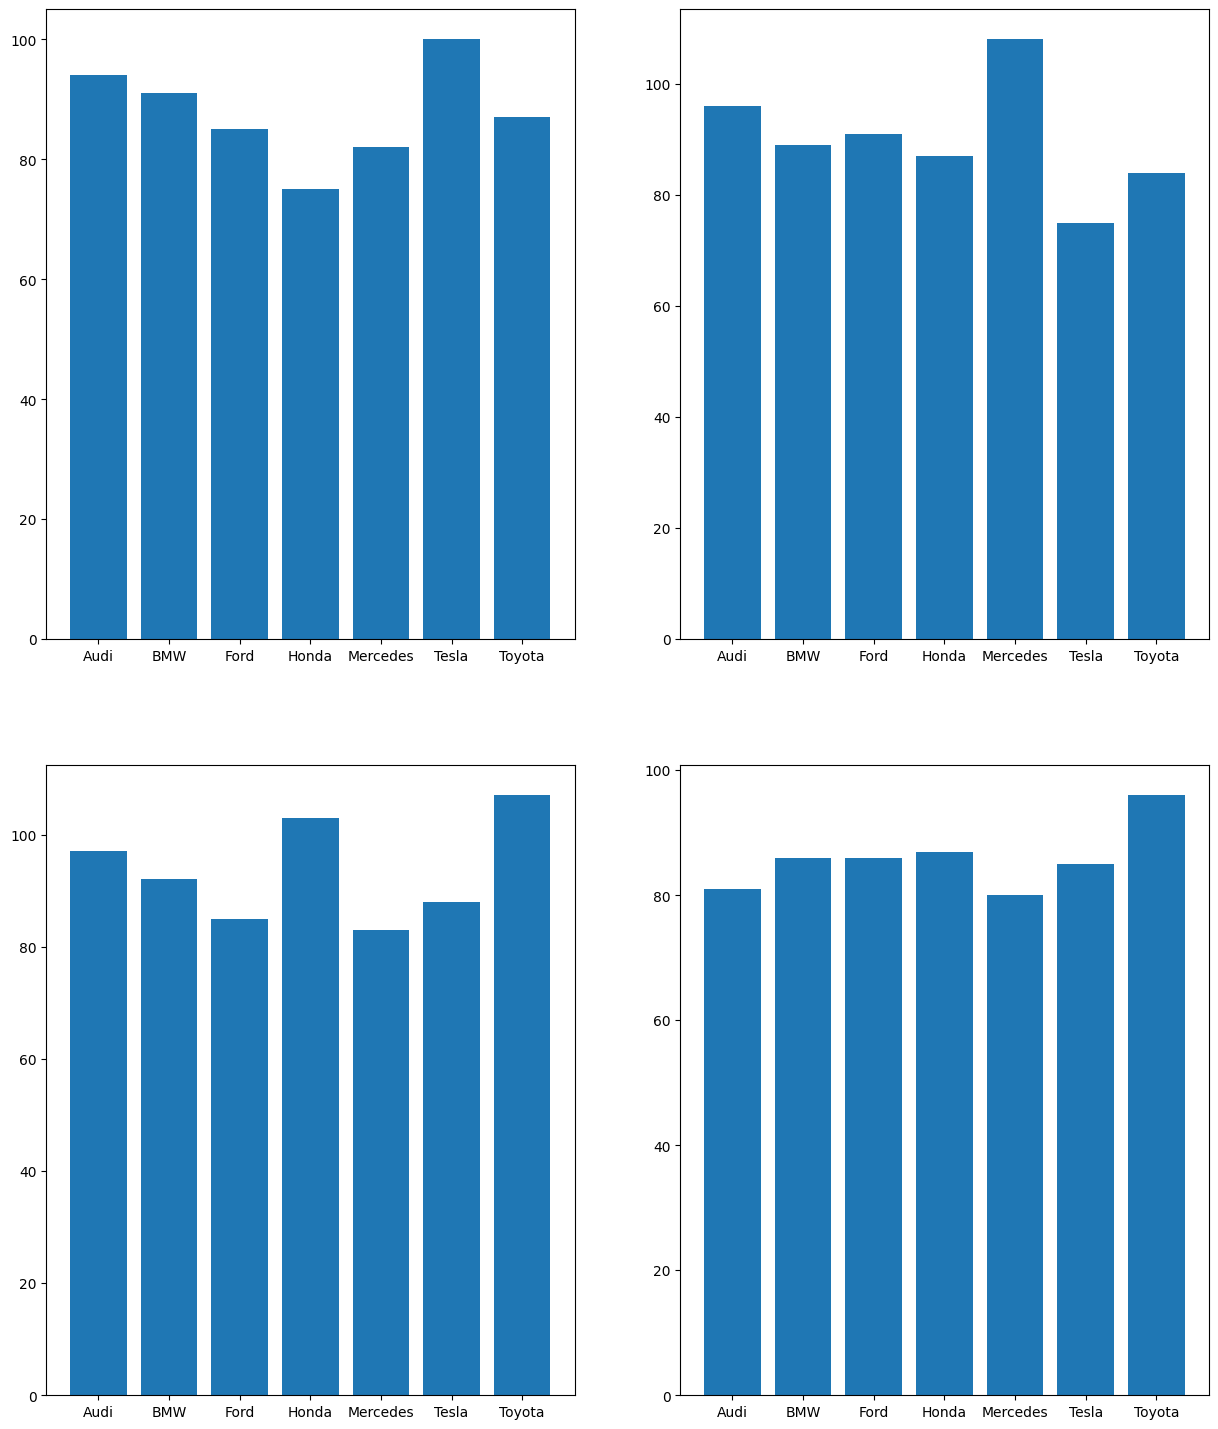

In [122]:
# WITH THIS ONE GRAPH WE CAN ANALYISE WHICH BRAND MAKING HOW MANY CARS OF DIFFERENT FEATURES
fig, x = plt.subplots(2,2,figsize = (15,18))
x[0,0].bar(fuel.index,fuel["Electric"])
x[0,1].bar(fuel.index,fuel["Petrol"])
x[1,0].bar(fuel.index,fuel["Diesel"])
x[1,1].bar(fuel.index,fuel["Hybrid"])

In [123]:
# FROM THIS GRAPH WE CAN ANALYSE MORE INFORMATION

In [124]:
# NOW LETS GOT TO CONNECT WITH PRICES
# RELATION BETWEEN PRICE AND MILEAGE
matrix = df[["Year","Mileage","Price"]].corr()
matrix

,Year,Mileage,Price
Year,1.000000,0.002282,-0.036805
Mileage,0.002282,1.000000,-0.008567
Price,-0.036805,-0.008567,1.000000


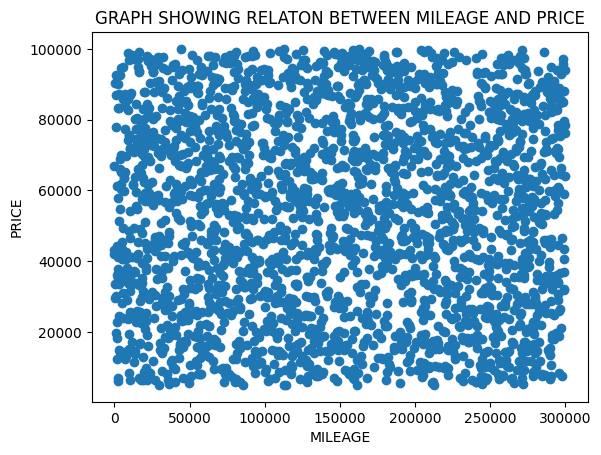

In [125]:
plt.scatter(df["Mileage"],df["Price"])
plt.title("GRAPH SHOWING RELATON BETWEEN MILEAGE AND PRICE")
plt.xlabel("MILEAGE")
plt.ylabel("PRICE")
plt.show()
# SO IT IS NOT GIVING A RELATION THERE

In [126]:
average = df.groupby("Brand")["Price"].apply(lambda x:x.mean())
print(average)
# THIS GIVES AVERAGE PRICE OF EACH BRAND




Brand
Audi        51953.424810
BMW         54157.114385
Ford        51593.254813
Honda       52050.283949
Mercedes    53191.090085
Tesla       53475.547471
Toyota      52078.728235
Name: Price, dtype: float64
